# Feature Engineering and Feature Selection Exercises
This notebook contains hands-on exercises for feature engineering and feature selection using Python.
Datasets used:
- Titanic (from seaborn)
- Iris (from sklearn)
- Breast Cancer (from sklearn)


## Part 2 – Feature Selection
### Exercise 4: Correlation-based selection
**Dataset:** Titanic dataset

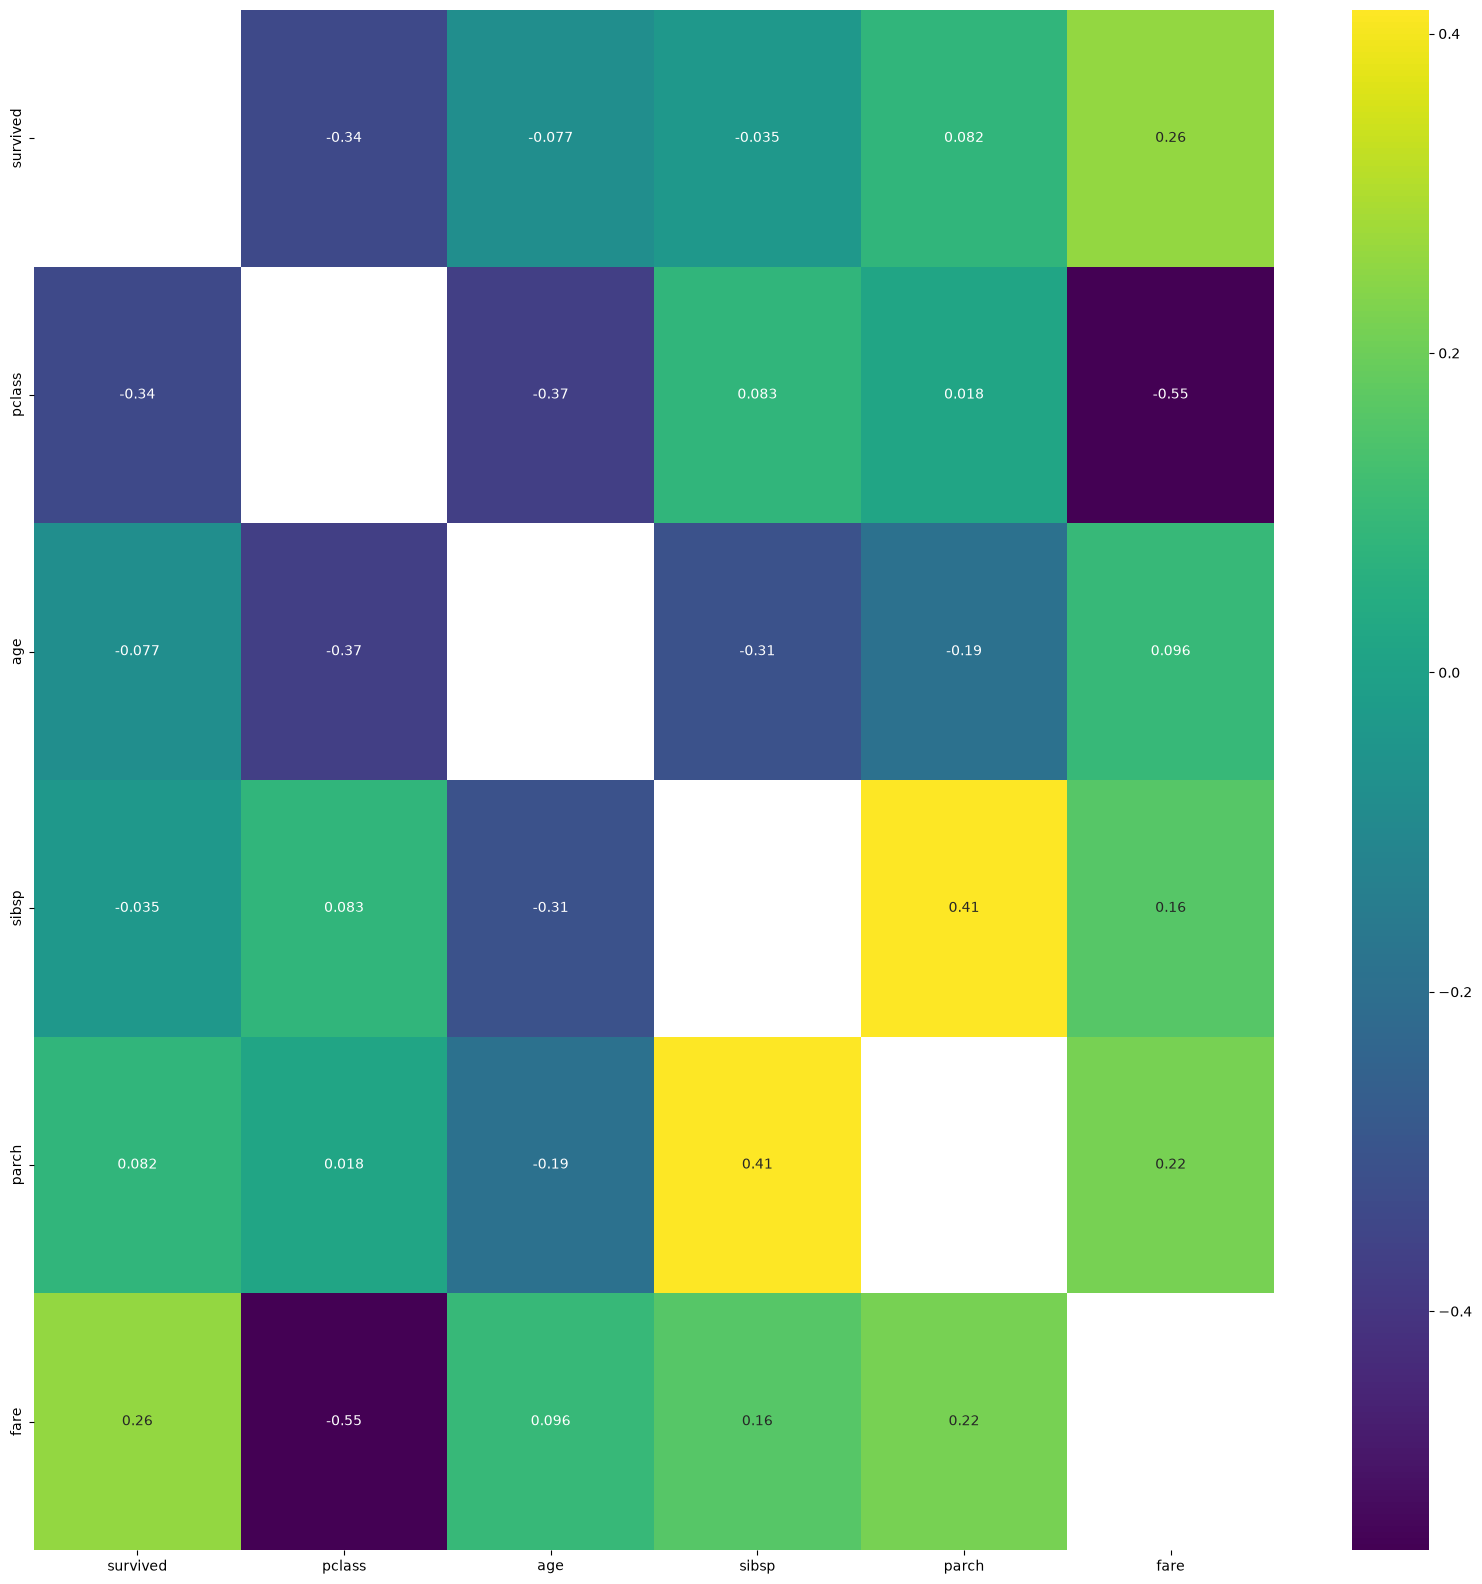

In [5]:
# Compute correlation matrix for numerical variables
# Drop variables with high correlation (>0.85)

import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps

list(colormaps)

Set = sns.load_dataset('titanic')

matrix = Set.select_dtypes(include=np.number).corr()
# filtered_matrix = matrix[matrix < 0.85]
filtered_matrix = matrix.where(matrix < 0.85)

feature_labels = matrix.index
plt.figure(figsize=(20,20))

g = sns.heatmap(filtered_matrix, annot=True, cmap="viridis")

### Exercise 5: Univariate feature selection
**Dataset:** Breast Cancer dataset (`sklearn.datasets.load_breast_cancer`)

In [4]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import pandas as pd


cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = cancer.target


# Select top 5 features

topFeatures = SelectKBest(score_func=f_classif, k=5)
topFeatures.fit_transform(X,y)
index = topFeatures.get_support()
selected = X.columns[index]

scores = pd.DataFrame({"Feature": selected,  
    "Score": topFeatures.scores_[index]}
)

scores = scores.sort_values(by="Score", ascending=False)
scores.index = pd.RangeIndex(start=1, stop=len(scores)+1, step=1)

print("Top 5 Features: ")
print(scores)


# Train/test split

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Logistic Regression

regressor = LogisticRegression(max_iter=10000)
regressor.fit(x_train, y_train)
Y_predict = regressor.predict(x_test)


# comparison between the prediction and target
accuracy = accuracy_score(y_test, Y_predict)
print("the given accuracy of Logistic Regression is: ", accuracy)

Top 5 Features: 
                Feature       Score
1  worst concave points  964.385393
2       worst perimeter  897.944219
3   mean concave points  861.676020
4          worst radius  860.781707
5        mean perimeter  697.235272
--------------
the given accuracy with Univariate Selection is:  0.956140350877193


### Exercise 6: Recursive Feature Elimination (RFE)

In [3]:
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score


cancer = load_breast_cancer(as_frame=True) #load the necessary data
X = cancer.data
y = cancer.target


#split the data ONCE, the comparison should be done from the same dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

# without RFE

model_all = LogisticRegression(max_iter=10000)
model_all.fit(X_train, y_train)
pred_all = model_all.predict(X_test)
accuracy_all = accuracy_score(y_test, pred_all)

# Use RFE with logistic regression to select top 7 features
rfe_estimator = LogisticRegression(max_iter=10000)
selector = RFE( estimator=rfe_estimator, n_features_to_select=7)

# Learn the best 7 features from training data
selector.fit(X_train, y_train)

# Transform datasets to contain only those 7 features
X_train_RFE = selector.transform(X_train)
X_test_RFE = selector.transform(X_test)

# Train classifier using only selected features
model_RFE = LogisticRegression(max_iter=10000)
model_RFE.fit(X_train_RFE, y_train)
pred_RFE = model_RFE.predict(X_test_RFE)
accuracy_RFE = accuracy_score(y_test, pred_RFE)


# Compare accuracy with and without RFE
print("Accuracy without RFE:", accuracy_all)
print("Accuracy with RFE:", accuracy_RFE)

Accuracy without RFE: 0.9766081871345029
Accuracy with RFE: 0.9415204678362573
